# Задание 1

In [11]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

## Загружаем данные, собираем базовые статистики полей

In [2]:
# Читаем файл с оценками
movies = pd.read_csv('movies_stats.csv')
movies.head()

,userId,movieId,rating,timestamp,title,genres
0,1,31,2.5,1260759144,Dangerous Minds (1995),Drama
1,1,1029,3.0,1260759179,Dumbo (1941),Animation|Children|Drama|Musical
2,1,1061,3.0,1260759182,Sleepers (1996),Thriller
3,1,1129,2.0,1260759185,Escape from New York (1981),Action|Adventure|Sci-Fi|Thriller
4,1,1172,4.0,1260759205,Cinema Paradiso (Nuovo cinema Paradiso) (1989),Drama


In [3]:
movies.dtypes

userId         int64
movieId        int64
rating       float64
timestamp      int64
title            str
genres           str
dtype: object

In [4]:
# Переводим timestamp unix в datetime
movies['timestamp'] = pd.to_datetime(movies['timestamp'], unit='s')

In [5]:
# Собираем основные статистики полей
movies.describe()

,userId,movieId,rating,timestamp
count,100004.000000,100004.000000,100004.000000,100004
mean,347.011310,12548.664363,3.543608,2005-10-18 12:38:06
min,1.000000,1.000000,0.500000,1995-01-09 11:46:49
25%,182.000000,1028.000000,3.000000,2000-08-09 19:03:44
50%,367.000000,2406.500000,4.000000,2005-03-10 02:30:22
75%,520.000000,5418.000000,4.000000,2011-01-28 05:28:15
max,671.000000,163949.000000,5.000000,2016-10-16 17:57:24
std,195.163838,26369.198969,1.058064,NaN


In [6]:
# Проверяем заполненность полей
movies.isna().mean()

userId       0.0
movieId      0.0
rating       0.0
timestamp    0.0
title        0.0
genres       0.0
dtype: float64

## Создаём список годов

In [7]:
# Создаём список годов
years = list(range(1950, 2011))
print(years)

[1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010]


## Пишем функцию production_year

In [8]:
# Функция для поиска года в названии фильма
def production_year(title):
    for year in years:
        if str(year) in title:
            return year
    return 1900

## Добавляем столбец year

In [9]:
movies['year'] = movies['title'].apply(production_year)
movies[['title', 'year', 'rating']].head()

,title,year,rating
0,Dangerous Minds (1995),1995,2.5
1,Dumbo (1941),1900,3.0
2,Sleepers (1996),1996,3.0
3,Escape from New York (1981),1981,2.0
4,Cinema Paradiso (Nuovo cinema Paradiso) (1989),1989,4.0


## Считаем средние рейтинги

In [10]:
# Считаем средний рейтинг по годам
year_rating = movies.groupby('year', as_index = False).agg(mean_rating = ('rating', 'mean'))
year_rating = year_rating.sort_values('mean_rating', ascending=False)
year_rating.head(50)

,year,mean_rating
8,1957,4.014241
23,1972,4.011136
3,1952,4.000000
5,1954,3.994220
2,1951,3.983539
25,1974,3.978704
13,1962,3.952446
1,1950,3.915254
28,1977,3.905786
15,1964,3.841492


## Проверяем связь года и рейтинга

<Axes: xlabel='year', ylabel='mean_rating'>

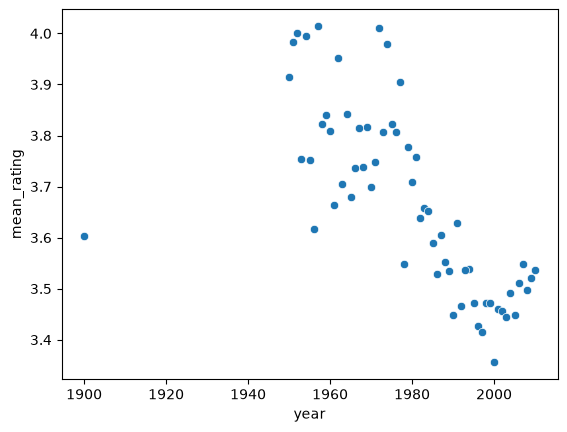

In [12]:
# Наблюдаем линейную взаимосвязь признаков
sns.scatterplot(data = year_rating, x = 'year', y = 'mean_rating')

In [37]:
# Считаем корреляцию без 1900 года
known_year_rating = year_rating.copy()
known_year_rating = known_year_rating[known_year_rating['year'] != 1900]

correlation, p_value = st.pearsonr(
    known_year_rating['year'],
    known_year_rating['mean_rating']
)

print('Корреляция:', correlation)
print('p-value:', p_value)

Корреляция: -0.8230903224875904
p-value: 3.96654046170119e-16


In [ ]:
# Вывод: на уровне значимости 5% в данной выборке мы отклоняем H0 об отсутствии зависимости между годом выпуска и средним рейтингом фильма этого года.
# По данным выборки наблюдается сильная отрицательная связь между годом и средним рейтингом фильма, выпущенного в этот год.
# Гипотеза о том, что раньше трава была зеленее в общем случае подтверждается, но без дополнительных данных о поле и возрасте, 
# вклада страт, а также времени проставления рейтинга - проводить причинно следственные связи и делать выводы не совсем корректно. 
# Вполне возможно что с годами люди присытились доступностью кино и/или рейтинг проставляли в разные годы непохожие группы пользователей.

